<a href="https://colab.research.google.com/github/TDev-GabrielNavarro/Age_guesser/blob/main/RUBRICA_SIMULACION_DISTRITAMIENTO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **RUBRICA SIMULACION - DISTRITAMIENTO**
### **PROFESOR:** ING. DARWIN MERCADO POLO
### **Grupo.** Gabriel Navarro, Daniel Escamilla, Sebastian Linares y Santiago Muñoz

## 1. Importación de Librerías

In [ ]:
import math
import matplotlib.pyplot as plt

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


## 2. Configuración Dinámica (Parámetros GLC, N y Proporciones del Modelo)


In [ ]:
# Modifica estos valores libremente para experimentar distintos escenarios

# 1. Cantidad de posiciones aleatorias a generar en el rectángulo envolvente
N_ITERACIONES = 100

# 2. Parámetros del Generador Lineal Congruencial (GLC Mixto)
# Recomendaciones de semillas (SEMILLA_X, SEMILLA_Y) y constantes (a, c) según el módulo m:
# - Para m = 100:
#     * Semillas: enteros positivos distintos de 0 y menores que 100 (ej. SEMILLA_X = 13, SEMILLA_Y = 27).
#     * Constantes: valores pequeños acordes a m (ej. a = 21, c = 17).
# - Para m = 1000:
#     * Semillas: enteros positivos distintos de 0 y menores que 1000 (ej. SEMILLA_X = 123, SEMILLA_Y = 457).
#     * Constantes: valores moderados acordes a m (ej. a = 21, c = 17).
# - Para m = 10000 (IDEAL):
#     * Semillas: enteros positivos distintos de 0 y menores que m (ej. SEMILLA_X = 123, SEMILLA_Y = 457).
#     * Constantes: valores acordes al tamaño de m (ej. a = 101, c = 137.)
SEMILLA_X = 123
SEMILLA_Y = 457
MULTIPLICADOR_A = 21
CONSTANTE_C = 17
MODULO_M = 1000  # Mayor que N_ITERACIONES (1000)

# 3. Dimensiones y proporciones del modelo geométrico (en km)
# Basado en lado del rombo = 10 km[cite: 5] y terna pitagórica 6-8-10 (dx=8, dy=6)
DX = 8.0          # Semidiagonal horizontal (mitad del ancho del rombo)
DY = 6.0          # Semidiagonal vertical (mitad del alto del rombo)

# Rectángulo envolvente (base L y altura A) en el cuadrante positivo
L_BASE = 2.0 * DX
A_ALTURA = 2.0 * DY

# Coordenadas del centro del rombo y de la Zona A (cuadrante positivo)
CENTRO_X = DX
CENTRO_Y = DY

# Radio de la Zona A (diámetro de 2 km -> radio de 1 km)
RADIO_ZONA_A = 1.0

# Coordenadas fijas de los centros de distribución (E1, E2, E3)[cite: 5]
CENTROS_DISTRIBUCION = {
    "E1": (CENTRO_X, CENTRO_Y),      # Centro del rombo / Zona A
    "E2": (L_BASE, CENTRO_Y),        # Esquina oriental (derecha)
    "E3": (0.0, CENTRO_Y),           # Esquina occidental (izquierda)
}

print("Configuración cargada:")
print(f"  - Iteraciones (N): {N_ITERACIONES} | Módulo GLC (m): {MODULO_M}")
print(f"  - Rectángulo envolvente: {L_BASE} km x {A_ALTURA} km")
print(f"  - Centro: ({CENTRO_X}, {CENTRO_Y}) | Radio Zona A: {RADIO_ZONA_A} km")

Configuración cargada:
  - Iteraciones (N): 100 | Módulo GLC (m): 1000
  - Rectángulo envolvente: 16.0 km x 12.0 km
  - Centro: (8.0, 6.0) | Radio Zona A: 1.0 km


## 3. Generador Lineal Congruencial (GLC Mixto)

In [ ]:
def generar_glc(xo, a, c, m):
    """
    Calcula el siguiente estado entero y el número pseudoaleatorio normalizado en [0, 1)
    mediante la relación: X_{i+1} = (a * X_i + c) % m
    """
    x_next = (a * xo + c) % m
    r = x_next / m
    return x_next, r

## 4. Lógica Geométrica (Rombo, Círculo y Distancias)

In [ ]:
def es_punto_valido_zona_b(x, y, dx=DX, dy=DY, cx=CENTRO_X, cy=CENTRO_Y, radio_a=RADIO_ZONA_A):
    """
    Evalúa si el punto (x, y) cae dentro de la Zona B (rombo) y fuera de la Zona A (círculo).
    Utiliza las pendientes de los lados del rombo respecto a la línea horizontal media y = cy.
    """
    # 1. Excluir Zona A (círculo centrado en (cx, cy) con radio_a)[cite: 2, 5]
    dist_cuadrada_centro = (x - cx) ** 2 + (y - cy) ** 2
    if dist_cuadrada_centro <= radio_a ** 2:
        return False

    # 2. Verificar pertenencia al rombo mediante pendientes
    pendiente_base = dy / dx  # Ej. 6 / 8 = 0.75
    x_izq = cx - dx
    x_der = cx + dx

    if y >= cy:  # Mitad superior del rombo
        # Evitar división por cero si x coincide exactamente con el vértice izquierdo o derecho
        if x == x_izq:
            m_izq_ok = (y == cy)
        else:
            m_izq = (y - cy) / (x - x_izq)
            m_izq_ok = (m_izq <= pendiente_base) if (x > x_izq) else (m_izq >= pendiente_base)

        if x == x_der:
            m_der_ok = (y == cy)
        else:
            m_der = (y - cy) / (x - x_der)
            m_der_ok = (m_der >= -pendiente_base) if (x < x_der) else (m_der <= -pendiente_base)

        return m_izq_ok and m_der_ok
    else:  # Mitad inferior del rombo
        if x == x_izq:
            m_izq_ok = (y == cy)
        else:
            m_izq = (y - cy) / (x - x_izq)
            m_izq_ok = (m_izq >= -pendiente_base) if (x > x_izq) else (m_izq <= -pendiente_base)

        if x == x_der:
            m_der_ok = (y == cy)
        else:
            m_der = (y - cy) / (x - x_der)
            m_der_ok = (m_der <= pendiente_base) if (x < x_der) else (m_der >= pendiente_base)

        return m_izq_ok and m_der_ok


def calcular_distancias_metropolitanas(x, y, centros=CENTROS_DISTRIBUCION):
    """
    Calcula la distancia metropolitana (|x - xc| + |y - yc|)[cite: 3]
    desde el punto (x, y) hasta cada centro de distribución[cite: 5].
    """
    distancias = {}
    for nombre, (xc, yc) in centros.items():
        distancias[nombre] = abs(x - xc) + abs(y - yc)
    return distancias

## 5. Ejecución de la Simulación

In [ ]:
def ejecutar_simulacion(
    n_iteraciones=N_ITERACIONES,
    xo_x=SEMILLA_X,
    xo_y=SEMILLA_Y,
    a=MULTIPLICADOR_A,
    c=CONSTANTE_C,
    m=MODULO_M,
    L=L_BASE,
    A=A_ALTURA,
):
    atenciones_centros = {nombre: 0 for nombre in CENTROS_DISTRIBUCION}
    distancias_totales = {nombre: 0.0 for nombre in CENTROS_DISTRIBUCION}

    puntos_validos_x, puntos_validos_y = [], []
    puntos_rechazados_x, puntos_rechazados_y = [], []
    centros_asignados = []

    validos = 0
    rechazados = 0

    for _ in range(n_iteraciones):
        xo_x, r1 = generar_glc(xo_x, a, c, m)
        xo_y, r2 = generar_glc(xo_y, a, c, m)

        # Escalamiento uniforme al intervalo [0, L] y [0, A][cite: 3]
        x = L * r1
        y = A * r2

        if es_punto_valido_zona_b(x, y):
            validos += 1
            puntos_validos_x.append(x)
            puntos_validos_y.append(y)

            distancias = calcular_distancias_metropolitanas(x, y)
            centro_ganador = min(distancias, key=distancias.get)

            atenciones_centros[centro_ganador] += 1
            distancias_totales[centro_ganador] += distancias[centro_ganador]
            centros_asignados.append(centro_ganador)
        else:
            rechazados += 1
            puntos_rechazados_x.append(x)
            puntos_rechazados_y.append(y)

    print("=" * 60)
    print(f"RESULTADOS DE LA SIMULACIÓN (N = {n_iteraciones}, m = {m})")
    print("=" * 60)
    print(f"Total posiciones generadas en rectángulo ({L} x {A} km): {n_iteraciones}")
    print(f"  - Válidos dentro de Zona B: {validos} ({(validos / n_iteraciones) * 100:.2f}%)")
    print(f"  - Rechazados (fuera rombo o en Zona A): {rechazados} ({(rechazados / n_iteraciones) * 100:.2f}%)\n")

    if validos > 0:
        for centro in CENTROS_DISTRIBUCION:
            porcentaje = (atenciones_centros[centro] / validos) * 100
            prom_dist = (
                distancias_totales[centro] / atenciones_centros[centro]
                if atenciones_centros[centro] > 0
                else 0.0
            )
            print(f"Centro {centro}:")
            print(f"  - Porcentaje de pedidos válidos atendidos: {porcentaje:.2f}%")
            print(f"  - Distancia promedio recorrida: {prom_dist:.2f} km\n")
    print("=" * 60)

    return (
        puntos_validos_x,
        puntos_validos_y,
        puntos_rechazados_x,
        puntos_rechazados_y,
        centros_asignados,
    )


x_vals, y_vals, x_rech, y_rech, asignaciones = ejecutar_simulacion()

RESULTADOS DE LA SIMULACIÓN (N = 100, m = 1000)
Total posiciones generadas en rectángulo (16.0 x 12.0 km): 100
  - Válidos dentro de Zona B: 51 (51.00%)
  - Rechazados (fuera rombo o en Zona A): 49 (49.00%)

Centro E1:
  - Porcentaje de pedidos válidos atendidos: 70.59%
  - Distancia promedio recorrida: 3.81 km

Centro E2:
  - Porcentaje de pedidos válidos atendidos: 13.73%
  - Distancia promedio recorrida: 3.34 km

Centro E3:
  - Porcentaje de pedidos válidos atendidos: 15.69%
  - Distancia promedio recorrida: 2.51 km



## 6. Generación de Gráficas

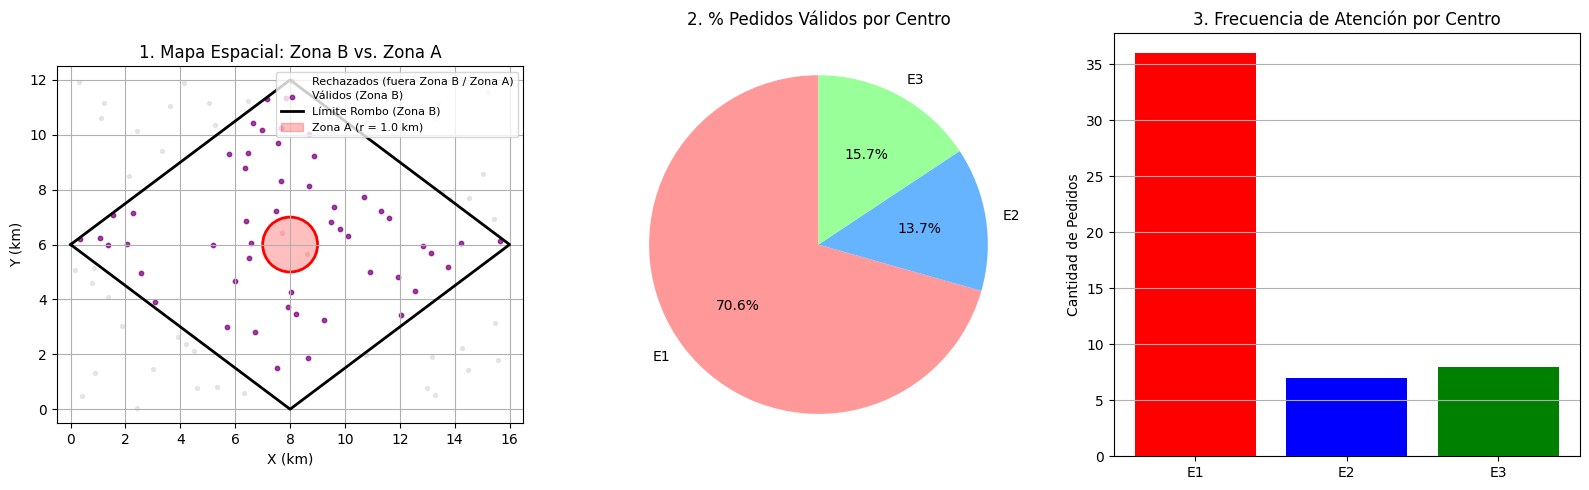

In [ ]:
def generar_graficas_dinamicas(x_vals, y_vals, x_rech, y_rech, asignaciones):
    plt.figure(figsize=(16, 5))

    # Gráfica 1: Mapa espacial con Zona B, Zona A y puntos simulados
    plt.subplot(1, 3, 1)

    if len(x_rech) > 0:
        plt.scatter(
            x_rech,
            y_rech,
            c="lightgray",
            s=8,
            alpha=0.5,
            label="Rechazados (fuera Zona B / Zona A)",
        )

    plt.scatter(
        x_vals,
        y_vals,
        c="purple",
        s=10,
        alpha=0.75,
        label="Válidos (Zona B)",
    )

    # Vértices del rombo calculados dinámicamente
    rombo_x = [CENTRO_X - DX, CENTRO_X, CENTRO_X + DX, CENTRO_X, CENTRO_X - DX]
    rombo_y = [CENTRO_Y, CENTRO_Y + DY, CENTRO_Y, CENTRO_Y - DY, CENTRO_Y]
    plt.plot(rombo_x, rombo_y, color="black", linewidth=2, label="Límite Rombo (Zona B)")

    # Círculo de la Zona A
    circulo_relleno = plt.Circle(
        (CENTRO_X, CENTRO_Y),
        RADIO_ZONA_A,
        color="red",
        fill=True,
        alpha=0.25,
        label=f"Zona A (r = {RADIO_ZONA_A} km)",
    )
    circulo_borde = plt.Circle(
        (CENTRO_X, CENTRO_Y), RADIO_ZONA_A, color="red", fill=False, linewidth=2
    )
    plt.gca().add_patch(circulo_relleno)
    plt.gca().add_patch(circulo_borde)

    plt.title("1. Mapa Espacial: Zona B vs. Zona A")
    plt.xlabel("X (km)")
    plt.ylabel("Y (km)")
    plt.xlim(-0.5, L_BASE + 0.5)
    plt.ylim(-0.5, A_ALTURA + 0.5)
    plt.gca().set_aspect("equal", adjustable="box")
    plt.legend(loc="upper right", fontsize=8)
    plt.grid(True)

    # Gráfica 2: Diagrama circular de porcentaje por centro
    plt.subplot(1, 3, 2)
    etiquetas = list(CENTROS_DISTRIBUCION.keys())
    valores = [asignaciones.count(c) for c in etiquetas]
    colores = ["#ff9999", "#66b3ff", "#99ff99"]

    if sum(valores) > 0:
        plt.pie(valores, labels=etiquetas, autopct="%1.1f%%", startangle=90, colors=colores)
    plt.title("2. % Pedidos Válidos por Centro")

    # Gráfica 3: Gráfico de barras de frecuencia por centro
    plt.subplot(1, 3, 3)
    plt.bar(etiquetas, valores, color=["red", "blue", "green"])
    plt.title("3. Frecuencia de Atención por Centro")
    plt.ylabel("Cantidad de Pedidos")
    plt.grid(axis="y")

    plt.tight_layout()
    plt.show()


generar_graficas_dinamicas(x_vals, y_vals, x_rech, y_rech, asignaciones)